In [1]:
import os

base_path = "data/Archive/small_images"

noisy_path = os.path.join(base_path, "noisy")
gt_path = os.path.join(base_path, "gt")

noisy_files = sorted(os.listdir(noisy_path))
gt_files = sorted(os.listdir(gt_path))

print("Noisy images:", len(noisy_files))
print("Ground truth images:", len(gt_files))

print("\nFirst 5 noisy files:")
print(noisy_files[:5])

print("\nFirst 5 ground truth files:")
print(gt_files[:5])

Noisy images: 2457
Ground truth images: 2457

First 5 noisy files:
['1000.tif', '1001.tif', '1002.tif', '1003.tif', '1004.tif']

First 5 ground truth files:
['1000.tif', '1001.tif', '1002.tif', '1003.tif', '1004.tif']


In [2]:
# Check whether all filenames match
noisy_set = set(noisy_files)
gt_set = set(gt_files)
print("All noisy files:", len(noisy_set))
print("All GT files:", len(gt_set))
print("Missing in GT:", noisy_set - gt_set)
print("Missing in Noisy:", gt_set - noisy_set)
print("All pairs matched:", noisy_set == gt_set)

All noisy files: 2457
All GT files: 2457
Missing in GT: set()
Missing in Noisy: set()
All pairs matched: True


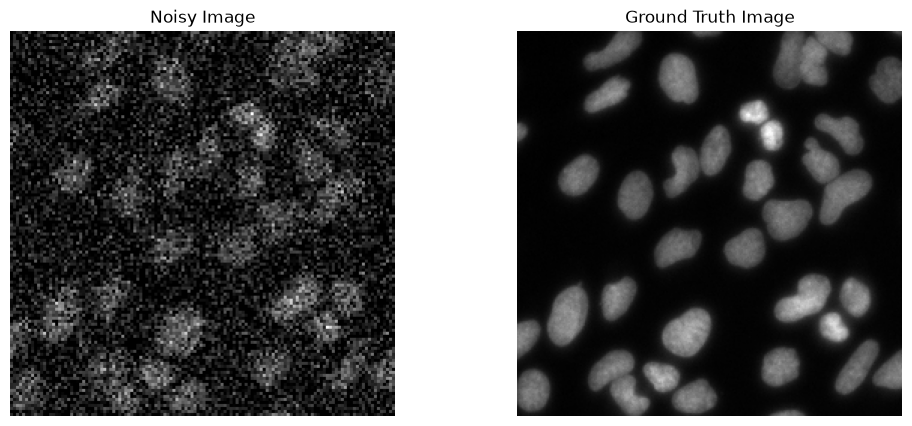

In [3]:
import tifffile
import matplotlib.pyplot as plt

# Select one image
filename = noisy_files[0]

# Load noisy and clean images
noisy_img = tifffile.imread(
    os.path.join(noisy_path, filename)
)

gt_img = tifffile.imread(
    os.path.join(gt_path, filename)
)

# Display images
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(noisy_img, cmap="gray")
plt.title("Noisy Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(gt_img, cmap="gray")
plt.title("Ground Truth Image")
plt.axis("off")

plt.show()

In [5]:
print("Noisy Image Properties")
print("----------------------")

print("Shape:", noisy_img.shape)
print("Data type:", noisy_img.dtype)
print("Minimum intensity:", noisy_img.min())
print("Maximum intensity:", noisy_img.max())
print("Mean intensity:", noisy_img.mean())
print("Standard deviation:", noisy_img.std())

print("\nGround Truth Properties")
print("----------------------")

print("Shape:", gt_img.shape)
print("Data type:", gt_img.dtype)
print("Minimum intensity:", gt_img.min())
print("Maximum intensity:", gt_img.max())
print("Mean intensity:", gt_img.mean())
print("Standard deviation:", gt_img.std())

Noisy Image Properties
----------------------
Shape: (256, 256)
Data type: uint16
Minimum intensity: 0
Maximum intensity: 71
Mean intensity: 10.10003662109375
Standard deviation: 10.278996951014792

Ground Truth Properties
----------------------
Shape: (256, 256)
Data type: uint16
Minimum intensity: 119
Maximum intensity: 1307
Mean intensity: 285.0247039794922
Standard deviation: 208.59196888153792


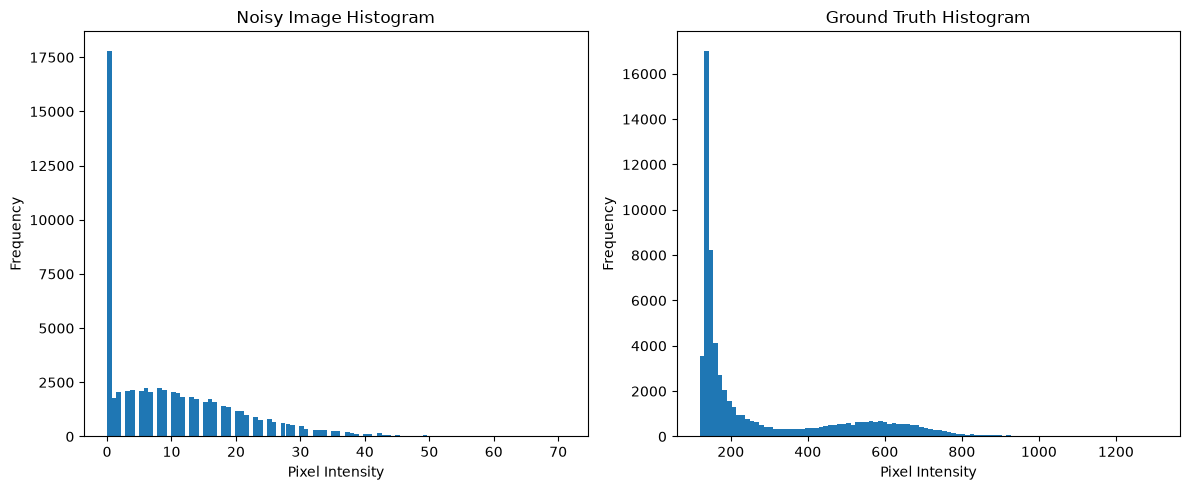

In [6]:
plt.figure(figsize=(12, 5))

# Noisy image histogram
plt.subplot(1, 2, 1)
plt.hist(noisy_img.ravel(), bins=100)
plt.title("Noisy Image Histogram")
plt.xlabel("Pixel Intensity")
plt.ylabel("Frequency")

# Ground truth histogram
plt.subplot(1, 2, 2)
plt.hist(gt_img.ravel(), bins=100)
plt.title("Ground Truth Histogram")
plt.xlabel("Pixel Intensity")
plt.ylabel("Frequency")

plt.tight_layout()
plt.show()

In [7]:
import numpy as np
sample_files = noisy_files[:10]
for filename in sample_files:

    noisy = tifffile.imread(
        os.path.join(noisy_path, filename)
    )

    clean = tifffile.imread(
        os.path.join(gt_path, filename)
    )
    print(f"\nImage: {filename}")
    print(
        "Noisy:",
        "Mean =", noisy.mean(),
        "Max =", noisy.max()
    )
    print(
        "Ground Truth:",
        "Mean =", clean.mean(),
        "Max =", clean.max()
    )


Image: 1000.tif
Noisy: Mean = 10.10003662109375 Max = 71
Ground Truth: Mean = 285.0247039794922 Max = 1307

Image: 1001.tif
Noisy: Mean = 7.80633544921875 Max = 82
Ground Truth: Mean = 195.841552734375 Max = 2214

Image: 1002.tif
Noisy: Mean = 8.10040283203125 Max = 60
Ground Truth: Mean = 211.66529846191406 Max = 1348

Image: 1003.tif
Noisy: Mean = 10.173828125 Max = 139
Ground Truth: Mean = 284.7366027832031 Max = 3744

Image: 1004.tif
Noisy: Mean = 9.81884765625 Max = 67
Ground Truth: Mean = 278.52220153808594 Max = 1268

Image: 1005.tif
Noisy: Mean = 10.01837158203125 Max = 92
Ground Truth: Mean = 283.18223571777344 Max = 2234

Image: 1006.tif
Noisy: Mean = 11.93121337890625 Max = 148
Ground Truth: Mean = 344.1854553222656 Max = 4085

Image: 1007.tif
Noisy: Mean = 8.7750244140625 Max = 117
Ground Truth: Mean = 236.0303497314453 Max = 3109

Image: 1008.tif
Noisy: Mean = 9.60333251953125 Max = 63
Ground Truth: Mean = 266.7566223144531 Max = 1537

Image: 1009.tif
Noisy: Mean = 12.317

In [8]:
import pandas as pd
results = []
for filename in noisy_files[:10]:
    noisy = tifffile.imread(
        os.path.join(noisy_path, filename)
    )
    clean = tifffile.imread(
        os.path.join(gt_path, filename)
    )
    results.append({
        "Filename": filename,
        "Noisy Mean": noisy.mean(),
        "GT Mean": clean.mean(),
        "Mean Ratio": clean.mean() / (noisy.mean() + 1e-8),
        "Noisy Max": noisy.max(),
        "GT Max": clean.max()
    })
df = pd.DataFrame(results)
display(df.round(2))

,Filename,Noisy Mean,GT Mean,Mean Ratio,Noisy Max,GT Max
0,1000.tif,10.10,285.02,28.22,71,1307
1,1001.tif,7.81,195.84,25.09,82,2214
2,1002.tif,8.10,211.67,26.13,60,1348
3,1003.tif,10.17,284.74,27.99,139,3744
4,1004.tif,9.82,278.52,28.37,67,1268
5,1005.tif,10.02,283.18,28.27,92,2234
6,1006.tif,11.93,344.19,28.85,148,4085
7,1007.tif,8.78,236.03,26.90,117,3109
8,1008.tif,9.60,266.76,27.78,63,1537
9,1009.tif,12.32,364.89,29.62,76,1666


In [9]:
import tifffile

noisy_file = os.path.join(noisy_path, "1000.tif")
gt_file = os.path.join(gt_path, "1000.tif")

# Inspect noisy image metadata
with tifffile.TiffFile(noisy_file) as tif:
    print("NOISY IMAGE METADATA")
    print("--------------------")

    for tag in tif.pages[0].tags.values():
        print(tag.name, ":", tag.value)

# Inspect ground truth metadata
with tifffile.TiffFile(gt_file) as tif:
    print("\nGROUND TRUTH METADATA")
    print("--------------------")

    for tag in tif.pages[0].tags.values():
        print(tag.name, ":", tag.value)

NOISY IMAGE METADATA
--------------------
ImageWidth : 256
ImageLength : 256
BitsPerSample : 16
Compression : 1
PhotometricInterpretation : 1
ImageDescription : {"shape": [256, 256]}
StripOffsets : (256,)
SamplesPerPixel : 1
RowsPerStrip : 256
StripByteCounts : (131072,)
XResolution : (1, 1)
YResolution : (1, 1)
ResolutionUnit : 1
Software : tifffile.py

GROUND TRUTH METADATA
--------------------
ImageWidth : 256
ImageLength : 256
BitsPerSample : 16
Compression : 1
PhotometricInterpretation : 1
ImageDescription : {"shape": [256, 256]}
StripOffsets : (256,)
SamplesPerPixel : 1
RowsPerStrip : 256
StripByteCounts : (131072,)
XResolution : (1, 1)
YResolution : (1, 1)
ResolutionUnit : 1
Software : tifffile.py


In [10]:
from tqdm import tqdm
import numpy as np
import pandas as pd

dataset_stats = []

for filename in tqdm(noisy_files):

    noisy = tifffile.imread(
        os.path.join(noisy_path, filename)
    )

    clean = tifffile.imread(
        os.path.join(gt_path, filename)
    )

    dataset_stats.append({
        "filename": filename,
        "noisy_mean": noisy.mean(),
        "gt_mean": clean.mean(),
        "mean_ratio": clean.mean() / (noisy.mean() + 1e-8),
        "noisy_std": noisy.std(),
        "gt_std": clean.std(),
        "noisy_p99": np.percentile(noisy, 99),
        "gt_p99": np.percentile(clean, 99)
    })

stats_df = pd.DataFrame(dataset_stats)

display(stats_df.describe().round(2))

100%|██████████| 2457/2457 [00:24<00:00, 98.76it/s] 


,noisy_mean,gt_mean,mean_ratio,noisy_std,gt_std,noisy_p99,gt_p99
count,2457.00,2457.00,2457.00,2457.00,2457.00,2457.00,2457.00
mean,10.38,291.24,27.70,11.46,260.23,47.00,1165.89
std,2.40,82.93,1.89,2.24,91.60,9.48,350.86
min,5.51,118.83,21.02,6.81,3.11,26.00,131.00
25%,8.92,241.26,27.01,9.94,203.45,40.00,948.00
50%,10.25,289.29,28.22,11.36,262.64,47.00,1182.65
75%,11.90,345.14,29.01,12.97,322.56,53.00,1374.00
max,65.48,2033.56,31.06,55.14,1663.81,161.00,4095.00


Pixel-wise correlation: 0.5824913177273104


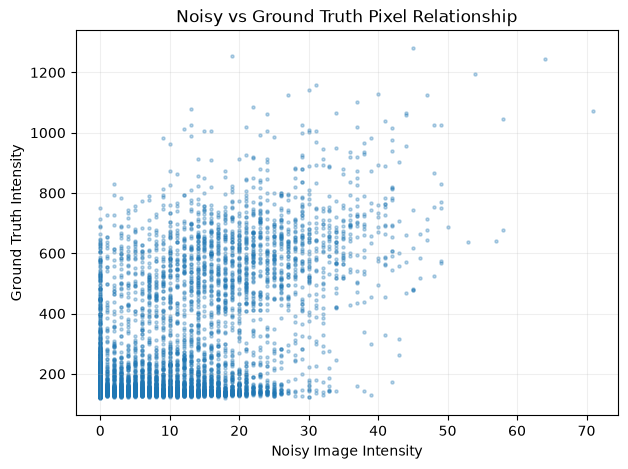

In [11]:
import numpy as np
import matplotlib.pyplot as plt

# Use image 1000
noisy = noisy_img.astype(np.float32)
clean = gt_img.astype(np.float32)

# Calculate pixel-wise correlation
correlation = np.corrcoef(
    noisy.ravel(),
    clean.ravel()
)[0, 1]

print("Pixel-wise correlation:", correlation)

# Scatter plot using sampled pixels
plt.figure(figsize=(7, 5))

plt.scatter(
    noisy.ravel()[::10],
    clean.ravel()[::10],
    alpha=0.3,
    s=5
)

plt.xlabel("Noisy Image Intensity")
plt.ylabel("Ground Truth Intensity")
plt.title("Noisy vs Ground Truth Pixel Relationship")
plt.grid(alpha=0.2)
plt.show()

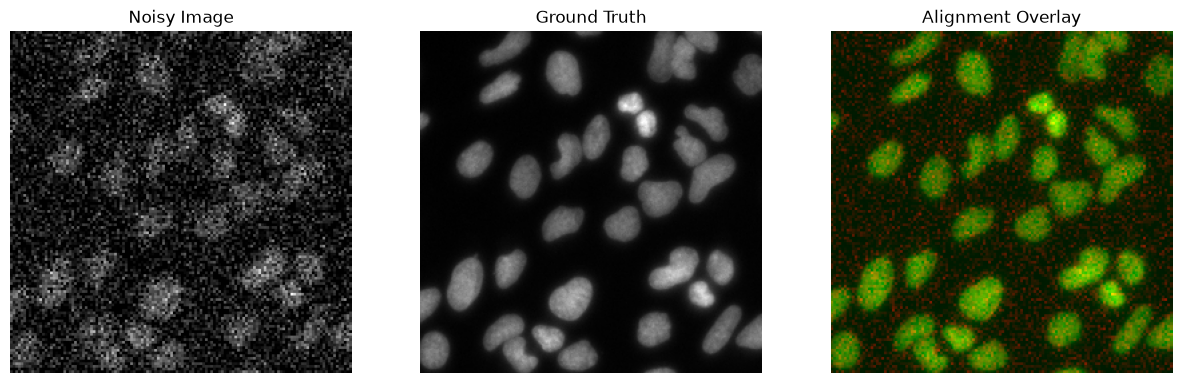

In [12]:
# Normalize for visualization only
noisy_vis = (
    noisy_img.astype(np.float32) /
    noisy_img.max()
)

gt_vis = (
    gt_img.astype(np.float32) /
    gt_img.max()
)

# Create RGB overlay
overlay = np.zeros((256, 256, 3))

overlay[:, :, 0] = noisy_vis  # Red channel
overlay[:, :, 1] = gt_vis     # Green channel

plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(noisy_vis, cmap="gray")
plt.title("Noisy Image")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(gt_vis, cmap="gray")
plt.title("Ground Truth")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(overlay)
plt.title("Alignment Overlay")
plt.axis("off")

plt.show()